# Gráfico das iterações dos testes T1–T3

Lê o `tabela.csv` gerado por `tool/gerar_tabela.py` e mostra como cada métrica muda de uma iteração para outra.

Dependências: `pip install pandas matplotlib notebook`, de preferência na `.venv` do projeto.

Ajuste os parâmetros da célula abaixo e rode tudo.

In [1]:
from pathlib import Path

# Tabela gerada por tool/gerar_tabela.py. A figura é gravada na mesma pasta.
TABELA = Path('~/Documents/TCC-notes/metricas/testes_usuarios_sem_ELA/tabela.csv').expanduser()

# 'olhar', 'toque/direcional' ou None para todas. Não misture modos: a economia
# de comandos não vale nas sessões por toque, e os tempos não são comparáveis.
MODO = 'olhar'

# (coluna do CSV, título do painel, fator de escala)
METRICAS = [
    ('duracao_s', 'Duração (s)', 1),
    ('comandos', 'Comandos', 1),
    ('mediana_s_comando', 'Mediana de s/comando', 1),
    ('eficiencia', 'Eficiência de navegação (%)', 100),
    ('economia', 'Economia de comandos (%)', 100),
    ('wpm', 'Palavras por minuto', 1),
]

In [2]:
import pandas as pd

tabela = pd.read_csv(TABELA)
dados = tabela if MODO is None else tabela[tabela['modo'] == MODO]
print(f'{len(dados)} de {len(tabela)} iterações (modo: {MODO or "todos"})')
dados[['teste', 'iteracao', 'modo', 'frase', *[m[0] for m in METRICAS]]]

2 de 2 iterações (modo: olhar)


,teste,iteracao,modo,frase,duracao_s,comandos,mediana_s_comando,eficiencia,economia,wpm
0,T1,1,olhar,SIM,425.312,127,2.7355,0.228346,-5.6842,0.0846
1,T1,2,olhar,SIM,78.977,32,2.1750,0.593750,-0.6842,0.4558


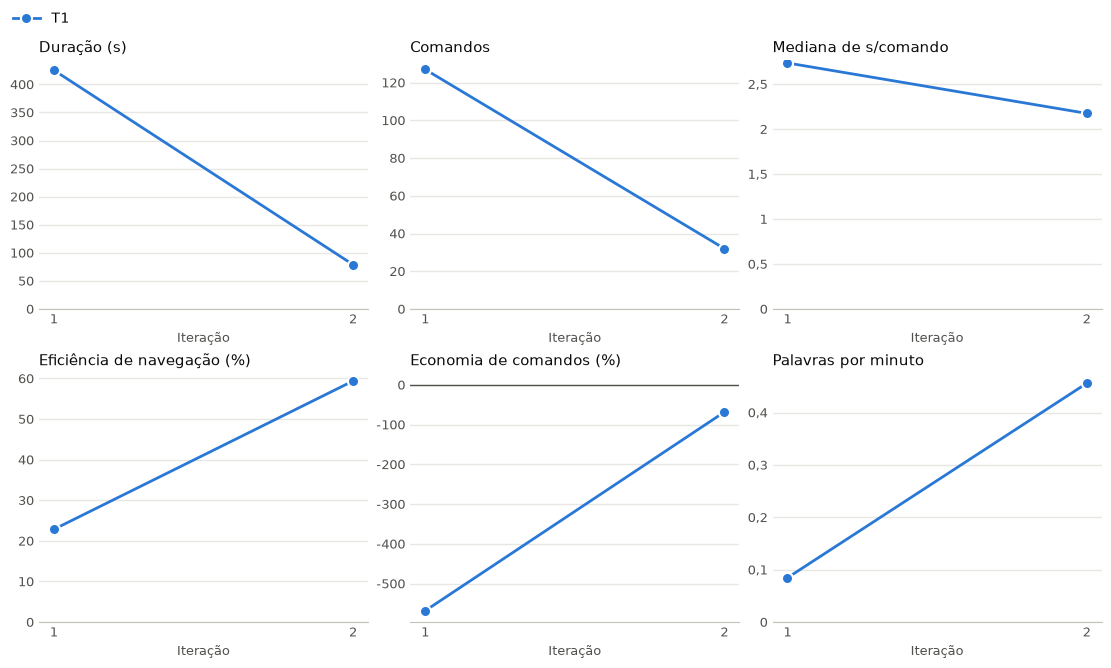

In [3]:
import math

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

# Cor e marcador fixos por teste, para o teste manter a aparência mesmo que outro
# não tenha dados e para continuar legível em impressão em preto e branco.
ESTILO = {
    'T1': {'color': '#2a78d6', 'marker': 'o'},
    'T2': {'color': '#eb6834', 'marker': 's'},
    'T3': {'color': '#1baf7a', 'marker': '^'},
}
virgula = FuncFormatter(lambda v, _: f'{v:g}'.replace('.', ','))

colunas = 3
linhas = math.ceil(len(METRICAS) / colunas)
fig, eixos = plt.subplots(linhas, colunas, figsize=(11, 3 * linhas + 0.6), layout='constrained', squeeze=False)

for eixo, (coluna, titulo, fator) in zip(eixos.flat, METRICAS):
    for teste, estilo in ESTILO.items():
        serie = dados[dados['teste'] == teste].sort_values('iteracao')
        eixo.plot(serie['iteracao'], serie[coluna] * fator, label=teste, linewidth=2, markersize=8,
                  markeredgecolor='white', markeredgewidth=1.5, **estilo)
    valores = dados[coluna] * fator
    if valores.min() >= 0:
        eixo.set_ylim(bottom=0)
    else:
        eixo.axhline(0, color='#52514e', linewidth=1)
    eixo.set_title(titulo, loc='left', fontsize=11, color='#0b0b0b')
    eixo.set_xlabel('Iteração', fontsize=9, color='#52514e')
    eixo.xaxis.set_major_locator(MaxNLocator(integer=True))
    eixo.yaxis.set_major_formatter(virgula)
    eixo.tick_params(colors='#52514e', labelsize=9, length=0)
    eixo.grid(axis='y', color='#e8e7e3', linewidth=1)
    eixo.set_axisbelow(True)
    for lado in ('top', 'right', 'left'):
        eixo.spines[lado].set_visible(False)
    eixo.spines['bottom'].set_color('#c3c2b7')

for eixo in eixos.flat[len(METRICAS):]:
    eixo.set_visible(False)

testes_com_dados = dados['teste'].unique()
marcas, nomes = eixos.flat[0].get_legend_handles_labels()
marcas, nomes = zip(*[(m, n) for m, n in zip(marcas, nomes) if n in testes_com_dados])
fig.legend(marcas, nomes, loc='outside upper left', ncols=3, frameon=False, fontsize=10)

for extensao in ('png', 'pdf'):
    fig.savefig(TABELA.with_name(f'grafico_iteracoes.{extensao}'), dpi=200)
plt.show()